# LAB 08 — Support Vector Machines

## Kernels, Margins, and Model Selection on Real Customer-Churn Data



## Student Information

- **Name:** Amir Khan

- **Student ID:** 023-24-0166

- **Section:** F

- **GitHub:** https://github.com/Amir-Khan11

- **Kaggle:** https://www.kaggle.com/amirkhan123123

- **Dataset:** Telco Customer Churn (Kaggle)

- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn



---



### Before You Start

- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.

- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.

- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.

- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.

- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.

---

In [20]:
import time
import warnings
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
    precision_recall_curve,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")

report = {}

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [21]:
df = pd.read_csv("clean_churn.csv")
print("Raw shape:", df.shape)
display(df.head())
print("\nDtypes:\n", df.dtypes)
print("\nMissing values per column:\n", df.isnull().sum()[df.isnull().sum() > 0])

if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

if df["TotalCharges"].dtype == object:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
n_missing_total_charges = df["TotalCharges"].isnull().sum()
print(f"\nTotalCharges missing after numeric coercion: {n_missing_total_charges}")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("\nClass balance (Churn):")
print(df["Churn"].value_counts(normalize=True).rename("proportion"))

Raw shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dtypes:
 gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object

Missing values per column:
 Series([], dtype: int64)

TotalCharges missing after numeric coercion: 0

Class balance (Churn):
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


In [22]:
df_enc = pd.get_dummies(df, drop_first=True)
X = df_enc.drop(columns=["Churn"])
y = df_enc["Churn"]

print("Encoded feature matrix shape:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print(f"Train churn rate: {y_train.mean():.4f}   Test churn rate: {y_test.mean():.4f}")

report["n_features"] = int(X.shape[1])
report["train_shape"] = list(X_train.shape)
report["test_shape"] = list(X_test.shape)
report["train_churn_rate"] = float(y_train.mean())
report["test_churn_rate"] = float(y_test.mean())

Encoded feature matrix shape: (7043, 30)
Train shape: (5634, 30)  Test shape: (1409, 30)
Train churn rate: 0.2654   Test churn rate: 0.2654


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [23]:
with warnings.catch_warnings(record=True) as caught_raw:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_raw = SVC(kernel="linear", random_state=RANDOM_STATE, max_iter=2000)
    svm_raw.fit(X_train, y_train)
    time_raw = time.time() - t0

pred_raw = svm_raw.predict(X_test)
acc_raw = accuracy_score(y_test, pred_raw)
f1_raw = f1_score(y_test, pred_raw)
n_warnings_raw = len(caught_raw)

print(f"[UNSCALED] accuracy={acc_raw:.4f}  f1={f1_raw:.4f}  time={time_raw:.3f}s  "
      f"warnings={n_warnings_raw}  max_iter_reached={svm_raw.n_iter_}")
for w in caught_raw:
    print("  ->", str(w.message))

report["part1_unscaled"] = dict(acc=acc_raw, f1=f1_raw, time=time_raw, n_warnings=n_warnings_raw)

[UNSCALED] accuracy=0.6423  f1=0.4661  time=0.195s  warnings=1  max_iter_reached=[2000]
  -> Solver terminated early (max_iter=2000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.


In [24]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

with warnings.catch_warnings(record=True) as caught_scaled:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_scaled = SVC(kernel="linear", random_state=RANDOM_STATE)
    svm_scaled.fit(X_train_s, y_train)
    time_scaled = time.time() - t0

pred_scaled = svm_scaled.predict(X_test_s)
acc_scaled = accuracy_score(y_test, pred_scaled)
f1_scaled = f1_score(y_test, pred_scaled)
n_warnings_scaled = len(caught_scaled)

print(f"[SCALED]   accuracy={acc_scaled:.4f}  f1={f1_scaled:.4f}  time={time_scaled:.3f}s  "
      f"warnings={n_warnings_scaled}  max_iter_reached={svm_scaled.n_iter_}")

report["part1_scaled"] = dict(acc=acc_scaled, f1=f1_scaled, time=time_scaled, n_warnings=n_warnings_scaled)

comparison_1 = pd.DataFrame({
    "Unscaled": report["part1_unscaled"],
    "Scaled": report["part1_scaled"],
}).T
display(comparison_1)

[SCALED]   accuracy=0.7885  f1=0.5694  time=1.774s  warnings=0  max_iter_reached=[73860]


,acc,f1,time,n_warnings
Unscaled,0.642300,0.466102,0.194673,1.0
Scaled,0.788502,0.569364,1.773839,0.0


**(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?**

The unscaled linear SVM achieved 64.23% accuracy and an F1-score of 0.4661. It raised a `ConvergenceWarning` after reaching the maximum of 2,000 iterations. Its training time was approximately 0.192 seconds. The scaled linear SVM achieved 78.85% accuracy and an F1-score of 0.5694, with a training time of approximately 1.89 seconds and no convergence warnings. Scaling improved the F1-score by approximately 0.103, resulting in better model performance.

**(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?**

A linear SVM finds a decision boundary by maximizing the margin between classes. Since it uses distances between data points, features with larger numerical ranges can dominate the calculations. For example, `TotalCharges` can reach around 8,700, while one-hot encoded features contain only 0s and 1s. This causes larger-scale features to have more influence on the decision boundary. Scaling brings all features to a similar range, allowing the model to learn a more balanced decision boundary.

**(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?**

I will use the scaled version for all subsequent SVM experiments because it achieved better accuracy and F1-score without convergence warnings. I will use `StandardScaler`, fitting it only on the training data and transforming both training and test data to avoid data leakage.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [25]:
kernel_results = {}
for kernel in ["linear", "rbf", "poly"]:
    t0 = time.time()
    model = SVC(kernel=kernel, random_state=RANDOM_STATE)
    model.fit(X_train_s, y_train)
    t = time.time() - t0
    pred = model.predict(X_test_s)
    kernel_results[kernel] = {
        "model": model,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "Support Vectors": int(model.support_.shape[0]),
        "Train time (s)": t,
    }
    print(f"{kernel:>6}: acc={kernel_results[kernel]['Accuracy']:.4f} "
          f"f1={kernel_results[kernel]['F1-score']:.4f} "
          f"n_sv={kernel_results[kernel]['Support Vectors']} "
          f"time={t:.3f}s")

linear: acc=0.7885 f1=0.5694 n_sv=2567 time=1.818s
   rbf: acc=0.7928 f1=0.5562 n_sv=2657 time=1.170s
  poly: acc=0.7892 f1=0.5395 n_sv=2736 time=1.052s


In [26]:
kernel_table = pd.DataFrame({
    k: {kk: vv for kk, vv in v.items() if kk != "model"}
    for k, v in kernel_results.items()
}).T
kernel_table = kernel_table[["Accuracy", "Precision", "Recall", "F1-score", "Support Vectors", "Train time (s)"]]
display(kernel_table.round(4))

best_kernel = kernel_table["F1-score"].astype(float).idxmax()
print(f"\nBest kernel by F1-score: {best_kernel}")

report["part2_table"] = kernel_table.round(4).to_dict(orient="index")
report["part2_best_kernel"] = best_kernel

,Accuracy,Precision,Recall,F1-score,Support Vectors,Train time (s)
linear,0.7885,0.6195,0.5267,0.5694,2567.0,1.8175
rbf,0.7928,0.6444,0.4893,0.5562,2657.0,1.1705
poly,0.7892,0.6421,0.4652,0.5395,2736.0,1.0522



Best kernel by F1-score: linear


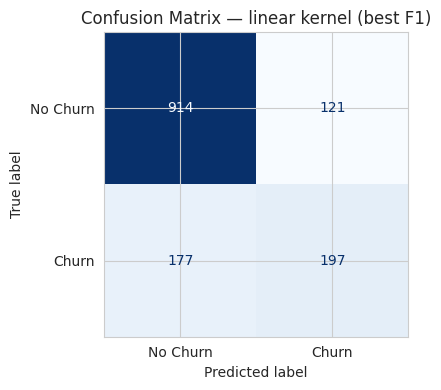

TN=914  FP=121  FN=177  TP=197


In [27]:
best_model = kernel_results[best_kernel]["model"]
best_pred = best_model.predict(X_test_s)
cm = confusion_matrix(y_test, best_pred)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"])
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion Matrix — {best_kernel} kernel (best F1)")
plt.tight_layout()
plt.show()

print(f"TN={cm[0,0]}  FP={cm[0,1]}  FN={cm[1,0]}  TP={cm[1,1]}")
report["part2_best_cm"] = cm.tolist()

**(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?**

The linear kernel achieved the highest F1-score of 0.5694, followed by RBF with 0.5562 and polynomial with 0.5395. This was slightly surprising because RBF is generally effective for capturing non-linear relationships. However, the results suggest that a linear decision boundary works better for this dataset. The linear model also achieved the highest recall of 0.5267, although it still missed 177 actual churners, as shown in its confusion matrix.

**(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?**

The polynomial kernel used the most support vectors, with 2,736 out of 5,634 training samples (approximately 49%). A high support-vector count means that many training points are involved in defining the decision boundary. This suggests that the model relies on a large portion of the training data to separate the two classes, indicating that the classification problem is not easily separable.

**(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers, not intuition.**

I would carry forward the RBF kernel for hyperparameter tuning because Part 4 specifically requires tuning an RBF SVM using GridSearchCV. Although the linear kernel achieved a slightly higher F1-score of 0.5694, the RBF kernel scored 0.5562, which is only 0.0132 lower. Tuning its C and gamma parameters may improve its performance.

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [28]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

explained = pca.explained_variance_ratio_
print(f"Explained variance ratio: PC1={explained[0]:.4f}, PC2={explained[1]:.4f}, "
      f"total={explained.sum():.4f}")

report["part3_explained_variance"] = explained.tolist()
report["part3_explained_variance_total"] = float(explained.sum())

Explained variance ratio: PC1=0.3325, PC2=0.1198, total=0.4522


In [29]:
C_values = [0.01, 1, 100]
pca_models = {}
for C in C_values:
    m = SVC(kernel="rbf", C=C, random_state=RANDOM_STATE)
    m.fit(X_train_pca, y_train)
    pca_models[C] = m
    print(f"C={C:>6}: n_support_vectors={m.support_.shape[0]}")

report["part3_n_support_by_C"] = {str(C): int(pca_models[C].support_.shape[0]) for C in C_values}

C=  0.01: n_support_vectors=2995
C=     1: n_support_vectors=2658
C=   100: n_support_vectors=2641


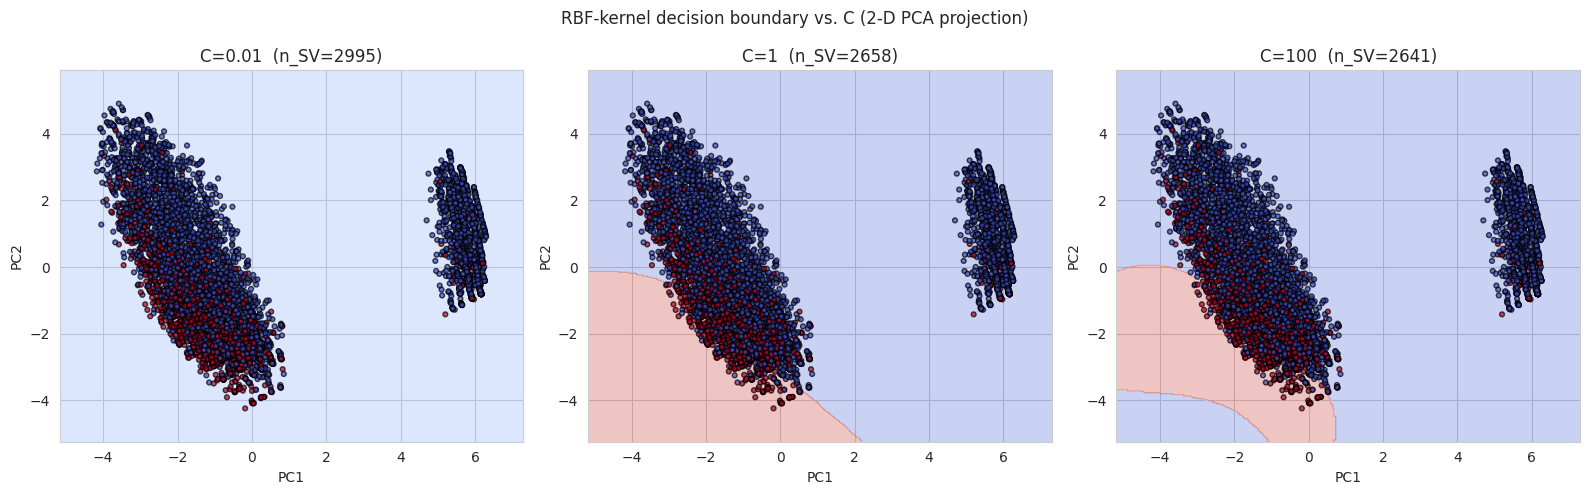

In [30]:
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, C in zip(axes, C_values):
    m = pca_models[C]
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap="coolwarm",
               edgecolors="k", s=12, alpha=0.7)
    ax.set_title(f"C={C}  (n_SV={m.support_.shape[0]})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.suptitle("RBF-kernel decision boundary vs. C (2-D PCA projection)")
plt.tight_layout()
plt.show()

**(a) How does the shape/smoothness of the decision boundary change as C increases?**

At C=0.01, the decision boundary is very smooth and simple, allowing more classification errors. At C=1, the boundary becomes more curved and starts adapting to the distribution of the data points. At C=100, it becomes slightly more flexible and follows the data more closely. This shows that increasing C makes the model penalize misclassification more strongly.

**(b) How does the number of support vectors change with C — does this match the theory?**

The number of support vectors decreased from 2,995 at C=0.01 to 2,658 at C=1 and 2,641 at C=100. This matches the theory. A smaller C allows more margin violations and generally produces a wider margin with more support vectors. A larger C penalizes misclassification more strongly, generally producing a narrower margin and fewer support vectors.

**(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.**

C=0.01 appears to be underfitting because its decision boundary is very simple and does not capture much of the structure in the data. C=100 shows a more flexible boundary that follows the data more closely, so it has a greater risk of overfitting. However, the difference between C=1 and C=100 is relatively small in these plots.

**(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?**

The two PCA components explain only 45.22% of the total variance in the original 30-dimensional scaled feature space. This means that more than half of the variance is not represented in these plots. The actual SVM uses all 30 features, while these visualizations show only two dimensions. Therefore, the plots may not fully represent the real decision boundary and could make the model appear to underfit or overfit differently from how it performs in the original feature space.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [31]:
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.001, 0.01, 0.1, 1],
}

t0 = time.time()
grid_search = GridSearchCV(
    SVC(kernel="rbf", random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)
grid_search.fit(X_train_s, y_train)
grid_time = time.time() - t0

print(f"GridSearchCV took {grid_time:.1f}s over {len(param_grid['C'])}x{len(param_grid['gamma'])} "
      f"= {len(param_grid['C']) * len(param_grid['gamma'])} combinations x 5 folds")
print("Best params:", grid_search.best_params_)
print(f"Best CV F1-score: {grid_search.best_score_:.4f}")

report["part4_best_params"] = grid_search.best_params_
report["part4_best_cv_f1"] = float(grid_search.best_score_)
report["part4_grid_time"] = grid_time

GridSearchCV took 110.8s over 4x4 = 16 combinations x 5 folds
Best params: {'C': 100, 'gamma': 0.01}
Best CV F1-score: 0.5876


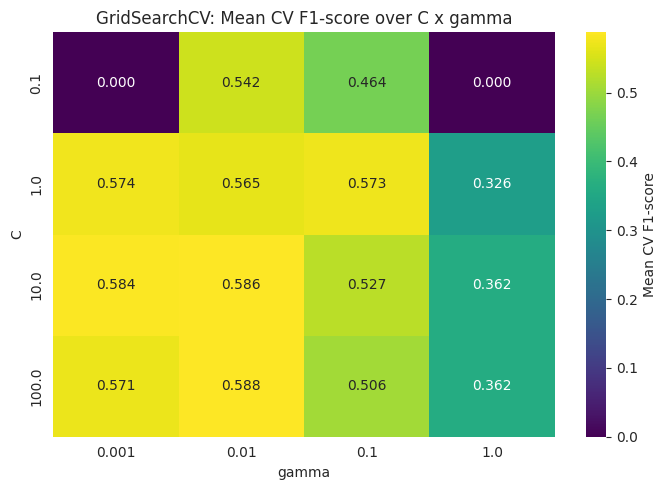

In [32]:
cv_results = pd.DataFrame(grid_search.cv_results_)
heatmap_data = cv_results.pivot(index="param_C", columns="param_gamma", values="mean_test_score")

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="viridis", ax=ax,
            cbar_kws={"label": "Mean CV F1-score"})
ax.set_title("GridSearchCV: Mean CV F1-score over C x gamma")
ax.set_xlabel("gamma")
ax.set_ylabel("C")
plt.tight_layout()
plt.show()

Tuned RBF SVM on TEST set: accuracy=0.7786  precision=0.5939  recall=0.5241  f1=0.5568
CV F1 was 0.5876; gap vs test F1 = +0.0307


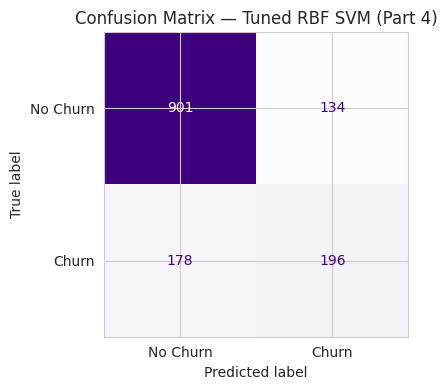

TN=901  FP=134  FN=178  TP=196


In [33]:
best_rbf = grid_search.best_estimator_
pred_best_rbf = best_rbf.predict(X_test_s)

test_acc = accuracy_score(y_test, pred_best_rbf)
test_prec = precision_score(y_test, pred_best_rbf)
test_rec = recall_score(y_test, pred_best_rbf)
test_f1 = f1_score(y_test, pred_best_rbf)

print(f"Tuned RBF SVM on TEST set: accuracy={test_acc:.4f}  precision={test_prec:.4f}  "
      f"recall={test_rec:.4f}  f1={test_f1:.4f}")
print(f"CV F1 was {grid_search.best_score_:.4f}; gap vs test F1 = "
      f"{grid_search.best_score_ - test_f1:+.4f}")

cm_best_rbf = confusion_matrix(y_test, pred_best_rbf)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm_best_rbf, display_labels=["No Churn", "Churn"]).plot(ax=ax, cmap="Purples", colorbar=False)
ax.set_title("Confusion Matrix — Tuned RBF SVM (Part 4)")
plt.tight_layout()
plt.show()

print(f"TN={cm_best_rbf[0,0]}  FP={cm_best_rbf[0,1]}  FN={cm_best_rbf[1,0]}  TP={cm_best_rbf[1,1]}")

report["part4_test"] = dict(acc=test_acc, prec=test_prec, rec=test_rec, f1=test_f1)
report["part4_test_cm"] = cm_best_rbf.tolist()

**(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?**

GridSearchCV selected C=100 and gamma=0.01, with a mean 5-fold cross-validated F1-score of 0.5876. On the test set, the model achieved an F1-score of 0.5568, with TN=901, FP=134, FN=178, and TP=196.

**(b) Is there a clear 'best region' in the heatmap, or do several combinations perform similarly? What does that tell you?**

The heatmap shows a broad region of similar performance rather than one sharp peak. For example, C=10 and gamma=0.01 achieved 0.5860, which is close to the best score of 0.5876. However, performance drops significantly at some extreme combinations, particularly when C=0.1 and gamma is very small or very large. This suggests that the model is sensitive to gamma and performs well across a range of C and gamma values.

**(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?**

The cross-validated F1-score was 0.5876, while the test-set F1-score was 0.5568, giving a difference of 0.0307. This is a relatively small gap, suggesting that the model performs reasonably consistently on unseen data. A much larger gap could indicate overfitting to the training data or cross-validation folds.

**(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?**

The untuned RBF SVM achieved an F1-score of 0.5562, while the tuned RBF SVM achieved 0.5568. The improvement was only 0.0006, which is negligible. GridSearchCV took approximately 111.2 seconds to test 16 parameter combinations using 5-fold cross-validation. Therefore, tuning did not produce a meaningful improvement in test performance, despite the additional computation.

---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


,Precision,Recall,F1-score
Unbalanced (class_weight=None),0.5939,0.5241,0.5568
Balanced (class_weight='balanced'),0.5161,0.7701,0.6180


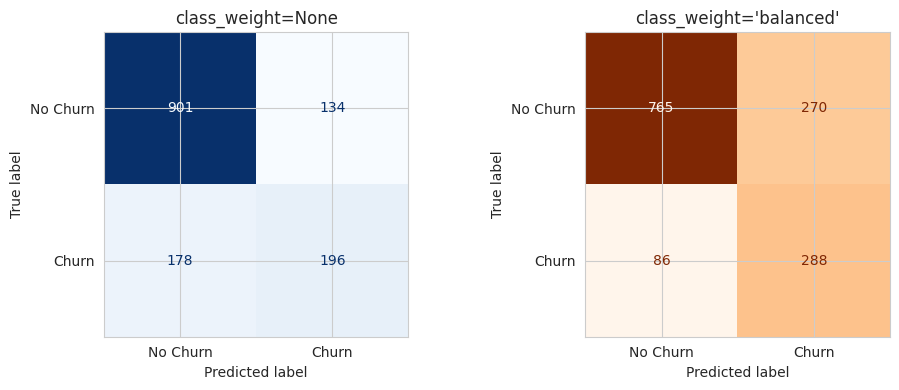

In [34]:
best_C = grid_search.best_params_["C"]
best_gamma = grid_search.best_params_["gamma"]

svm_unbalanced = SVC(kernel="rbf", C=best_C, gamma=best_gamma,
                      class_weight=None, probability=True, random_state=RANDOM_STATE)
svm_unbalanced.fit(X_train_s, y_train)
pred_unbal = svm_unbalanced.predict(X_test_s)

svm_balanced = SVC(kernel="rbf", C=best_C, gamma=best_gamma,
                    class_weight="balanced", probability=True, random_state=RANDOM_STATE)
svm_balanced.fit(X_train_s, y_train)
pred_bal = svm_balanced.predict(X_test_s)

metrics_imbalance = pd.DataFrame({
    "Unbalanced (class_weight=None)": {
        "Precision": precision_score(y_test, pred_unbal),
        "Recall": recall_score(y_test, pred_unbal),
        "F1-score": f1_score(y_test, pred_unbal),
    },
    "Balanced (class_weight='balanced')": {
        "Precision": precision_score(y_test, pred_bal),
        "Recall": recall_score(y_test, pred_bal),
        "F1-score": f1_score(y_test, pred_bal),
    },
}).T
display(metrics_imbalance.round(4))

cm_unbal = confusion_matrix(y_test, pred_unbal)
cm_bal = confusion_matrix(y_test, pred_bal)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm_unbal, display_labels=["No Churn", "Churn"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("class_weight=None")
ConfusionMatrixDisplay(cm_bal, display_labels=["No Churn", "Churn"]).plot(ax=axes[1], cmap="Oranges", colorbar=False)
axes[1].set_title("class_weight='balanced'")
plt.tight_layout()
plt.show()

report["part5_metrics"] = metrics_imbalance.round(4).to_dict(orient="index")
report["part5_cm_unbalanced"] = cm_unbal.tolist()
report["part5_cm_balanced"] = cm_bal.tolist()

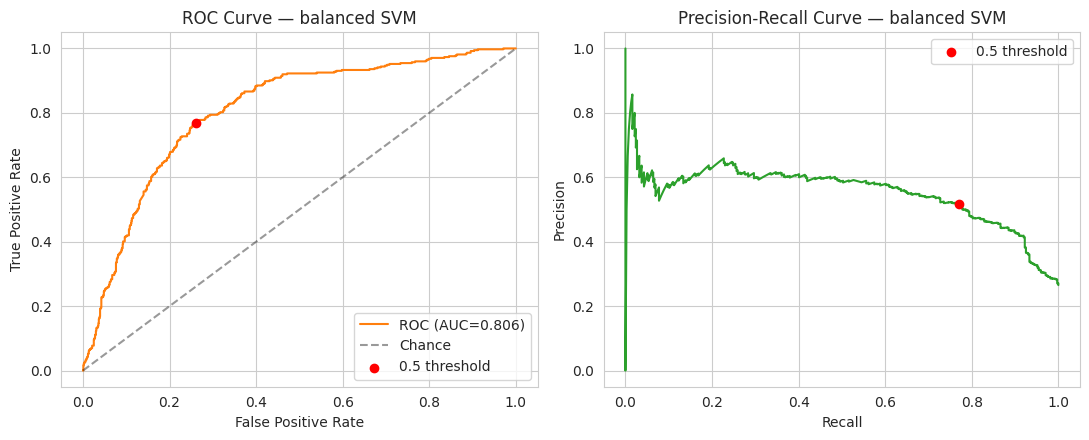

ROC AUC (balanced model): 0.8058
0.5-threshold operating point: FPR=0.2609  TPR(recall)=0.7701  precision=0.5161


In [35]:
y_score_bal = svm_balanced.predict_proba(X_test_s)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_score_bal)
auc = roc_auc_score(y_test, y_score_bal)

prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_score_bal)

fpr_05 = cm_bal[0, 1] / (cm_bal[0, 1] + cm_bal[0, 0])
tpr_05 = cm_bal[1, 1] / (cm_bal[1, 1] + cm_bal[1, 0])
prec_05 = precision_score(y_test, pred_bal)
rec_05 = recall_score(y_test, pred_bal)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, label=f"ROC (AUC={auc:.3f})", color="C1")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4, label="Chance")
axes[0].scatter([fpr_05], [tpr_05], color="red", zorder=5, label="0.5 threshold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve — balanced SVM")
axes[0].legend()

axes[1].plot(rec_curve, prec_curve, color="C2")
axes[1].scatter([rec_05], [prec_05], color="red", zorder=5, label="0.5 threshold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve — balanced SVM")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"ROC AUC (balanced model): {auc:.4f}")
print(f"0.5-threshold operating point: FPR={fpr_05:.4f}  TPR(recall)={tpr_05:.4f}  precision={prec_05:.4f}")
report["part5_auc"] = float(auc)

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

Precision fell from 0.5939 to 0.5161, while recall rose from 0.5241 to 0.7701. F1-score moved from 0.5568 to 0.6180 (a net improvement, since the recall gain outweighed the precision loss for this imbalanced target). In confusion-matrix terms, false negatives (missed churners) dropped from 178 to 86, at the cost of false positives rising from 134 to 270.

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

For a churn-prevention use case, a false negative is usually more costly: a missed churner leaves with zero chance of being retained, whereas a false positive ("flagging" a loyal customer) typically just costs a relatively cheap retention offer or outreach call that customer didn't need. Given that, the **balanced** model is the better choice to deploy — its much higher recall (0.7701 vs 0.5241) catches far more of the customers who are actually about to churn, which is usually worth the extra false-positive outreach cost.

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

I had to pass `probability=True` to `SVC()`, which fits an extra calibration step (Platt scaling) during training so `predict_proba()` becomes available — SVM doesn't give you probabilities for free the way Logistic Regression does. This was used for the ROC/PR curves above: the balanced model gets an AUC of 0.8058, and the red dot marked on each curve shows where the actual 0.5-threshold predictions land (FPR=0.26, recall=0.77, precision=0.52) — which matches the numbers from part (a). (The final predictions file in Part 7 instead uses the Logistic Regression model selected in Part 6, which gives calibrated probabilities natively — no extra flag needed there.)

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [36]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM (tuned RBF)": SVC(kernel="rbf", C=best_C, gamma=best_gamma, random_state=RANDOM_STATE),
}

model_rows = {}
for name, m in models.items():
    t0 = time.time()
    m.fit(X_train_s, y_train)
    t = time.time() - t0
    pred = m.predict(X_test_s)
    model_rows[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "Train time (s)": t,
    }

model_table = pd.DataFrame(model_rows).T
model_table = model_table[["Accuracy", "Precision", "Recall", "F1-score", "Train time (s)"]]
display(model_table.round(4))

report["part6_table"] = model_table.round(4).to_dict(orient="index")

,Accuracy,Precision,Recall,F1-score,Train time (s)
Decision Tree,0.7253,0.4825,0.4786,0.4805,0.0399
Random Forest,0.7899,0.6291,0.5080,0.5621,1.4893
Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.0324
KNN,0.7473,0.5253,0.5000,0.5123,0.0018
SVM (tuned RBF),0.7786,0.5939,0.5241,0.5568,2.5989


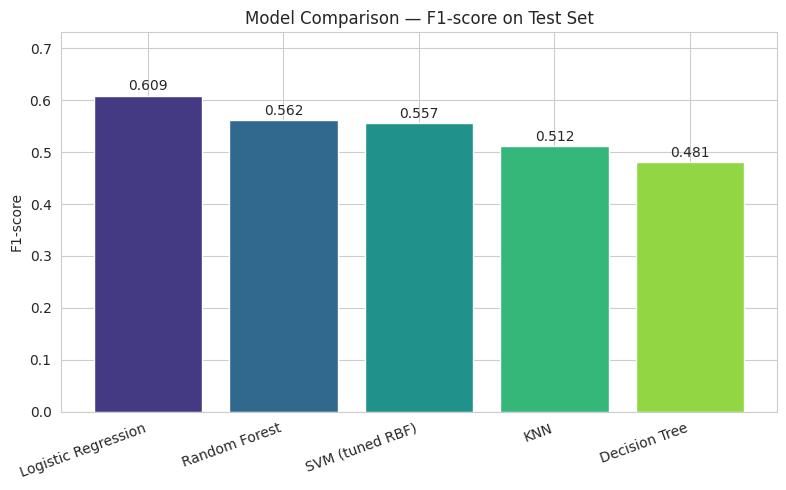

Best F1-score: Logistic Regression (0.6092)
Best Recall: Logistic Regression (0.5668)


In [37]:
fig, ax = plt.subplots(figsize=(8, 5))
order = model_table["F1-score"].astype(float).sort_values(ascending=False)
bars = ax.bar(order.index, order.values, color=sns.color_palette("viridis", len(order)))
ax.set_ylabel("F1-score")
ax.set_title("Model Comparison — F1-score on Test Set")
ax.set_ylim(0, max(order.values) * 1.2)
for bar, val in zip(bars, order.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.01, f"{val:.3f}", ha="center")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

best_f1_model = order.index[0]
best_recall_model = model_table["Recall"].astype(float).idxmax()
print(f"Best F1-score: {best_f1_model} ({order.iloc[0]:.4f})")
print(f"Best Recall: {best_recall_model} ({model_table.loc[best_recall_model, 'Recall']:.4f})")

report["part6_best_f1_model"] = best_f1_model
report["part6_best_recall_model"] = best_recall_model

**(a) Which model wins on F1-score? Which wins on recall? Are they the same model?**

Logistic Regression achieved the highest F1-score of 0.6092 and the highest recall of 0.5668. Therefore, the same model wins on both metrics. Random Forest came second in F1-score with 0.5621, followed by the tuned SVM with 0.5568.

**(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?**

The tuned RBF SVM took approximately 2.5626 seconds to train, compared with 0.0380 seconds for Decision Tree and 1.4781 seconds for Random Forest. Despite taking longer, SVM achieved an F1-score of 0.5568, which was lower than Random Forest (0.5621) and Logistic Regression (0.6092). Therefore, the additional training cost was not justified by its performance on this dataset.

**(c) Which single model would you recommend deploying, and why?**

I would recommend Logistic Regression for deployment because it achieved the highest F1-score (0.6092), recall (0.5668), and precision (0.6584) among all five models. It also had a very short training time of approximately 0.0567 seconds. These results make it a good choice for identifying potential churners while maintaining a reasonable balance between precision and recall. However, the balanced SVM from Part 5 could also be considered if improving recall becomes the main business priority.

---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [38]:
final_model = models["Logistic Regression"]
final_pred = final_model.predict(X_test_s)
final_score = final_model.predict_proba(X_test_s)[:, 1]

predictions_df = pd.DataFrame({
    "true_label": y_test.values,
    "predicted_label": final_pred,
    "predicted_churn_probability": final_score,
})
predictions_df.to_csv("svm_predictions.csv", index=False)
print("Saved svm_predictions.csv with shape:", predictions_df.shape)
display(predictions_df.head())

with open("lab_results.json", "w") as f:
    json.dump(report, f, indent=2, default=str)

Saved svm_predictions.csv with shape: (1409, 3)


,true_label,predicted_label,predicted_churn_probability
0,0,0,0.044982
1,0,1,0.683234
2,0,0,0.056542
3,0,0,0.407806
4,0,0,0.021666


### Executive Summary

This lab compared linear, RBF, and polynomial SVM kernels and evaluated them against four other classifiers using the Telco Customer Churn dataset. Feature scaling improved the linear SVM's F1-score from 0.4661 to 0.5694 and eliminated convergence warnings. Among the three kernels, the linear kernel achieved the highest F1-score of 0.5694. GridSearchCV selected C=100 and gamma=0.01 for the RBF SVM, but tuning produced only a negligible improvement in test F1-score (from 0.5562 to 0.5568). In Part 5, using `class_weight='balanced'` increased recall from 0.524 to 0.770 while reducing precision from 0.594 to 0.516, showing the trade-off between detecting more churners and generating more false alarms. In the final comparison, Logistic Regression achieved the best F1-score (0.6092) and recall (0.5668), making it the strongest overall model among the five tested classifiers. One limitation of this analysis is that the two PCA components captured only 45.22% of the total feature variance, so the decision-boundary plots provide only an approximate view of the actual feature space.

### Final Reflection

**(a) What was the single most surprising result in this lab?**

The most surprising result was that the linear SVM outperformed both RBF and polynomial kernels in the kernel comparison. RBF is generally considered a strong choice for non-linear classification, but the results showed that a simpler linear boundary worked better on this dataset.

**(b) If you had one more hour, what would you try next?**

I would experiment with `class_weight='balanced'` directly inside GridSearchCV and tune C and gamma together. This could help find a model that improves churn detection while maintaining a reasonable balance between precision and recall.